# Diabetes Readmission: Baseline Model Training

This notebook trains five untuned candidate classifiers on the training partition only. Every model uses the same patient-grouped split and its own sklearn preprocessing pipeline. The holdout is not used for fitting.

Candidates: Logistic Regression, Decision Tree, Random Forest, Linear SVM, and XGBoost. Class weighting is used to address the observed class imbalance; no synthetic records are created. Linear SVM exposes decision scores rather than probabilities, so calibration can be assessed later if it is considered for selection.

This is an educational hospital-readmission task, not diabetes diagnosis, treatment, or medical advice. No model is selected or serialized in this phase.

In [2]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

DATA_RELATIVE = Path("data/raw/diabetes/source/diabetic_data.csv")
PROJECT_ROOT = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / DATA_RELATIVE).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Could not locate {DATA_RELATIVE} from {Path.cwd()}")
sys.path.insert(0, str(PROJECT_ROOT))

from backend.app.ml.diabetes.preprocessing import load_diabetes_dataset, split_by_patient
from backend.app.ml.diabetes.training import train_candidate_models

predictors, target, patient_groups = load_diabetes_dataset(PROJECT_ROOT / DATA_RELATIVE)
data_split = split_by_patient(predictors, target, patient_groups, random_state=42)
split_summary = pd.DataFrame({
    "rows": [len(data_split.X_train), len(data_split.X_test)],
    "unique patients": [data_split.groups_train.nunique(), data_split.groups_test.nunique()],
    "positive share (<30)": [data_split.y_train.mean(), data_split.y_test.mean()],
}, index=["train", "holdout (reserved for evaluation)"])
display(split_summary.style.format({"positive share (<30)": "{:.2%}"}))
assert set(data_split.groups_train).isdisjoint(data_split.groups_test)

,rows,unique patients,positive share (<30)
train,81412,57240,11.16%
holdout (reserved for evaluation),20354,14278,11.16%


## Fit Baseline Candidates
The following cell can take several minutes. It reports training time and estimator class only; performance metrics and model selection belong to the next phase.

In [3]:
training_run = train_candidate_models(
    data_split.X_train,
    data_split.y_train,
    random_state=42,
)

training_summary = pd.DataFrame([
    {
        "candidate": name,
        "estimator": type(pipeline.named_steps["classifier"]).__name__,
        "fit_seconds": training_run.fit_seconds[name],
    }
    for name, pipeline in training_run.models.items()
]).sort_values("candidate").reset_index(drop=True)
display(training_summary.style.format({"fit_seconds": "{:.1f}"}))
print(f"Trained candidates: {len(training_run.models)}")
print("Models remain in notebook memory; no artifacts or metrics were saved in this phase.")

,candidate,estimator,fit_seconds
0,decision_tree,DecisionTreeClassifier,33.6
1,linear_svm,LinearSVC,25.3
2,logistic_regression,LogisticRegression,8.9
3,random_forest,RandomForestClassifier,27.6
4,xgboost,XGBClassifier,3.4


Trained candidates: 5
Models remain in notebook memory; no artifacts or metrics were saved in this phase.


## Scope And Guardrails

These are baseline fits, not tuned or clinically validated models. The next phase will evaluate candidates consistently on the reserved grouped holdout and with cross-validation, reporting multiple metrics and trade-offs. Hyperparameter search, SHAP analysis, and serialization are later phases.

Training rows are historical encounters from the documented UCI dataset. Predictions must not be presented as diagnoses or medical advice.

## Phase 6: Model Comparison

Cross-validation below uses three stratified patient-grouped folds from the training partition only. The separate grouped holdout is evaluated once. Accuracy, precision, recall, F1, ROC-AUC, PR-AUC, fit time, and confusion matrices are reported; these results do not establish clinical effectiveness. Precision-recall trade-offs are shown without selecting an overall best model. Linear SVM uses decision scores, not calibrated probabilities.

Holdout metrics; hard-label metrics use each estimator's default decision threshold.


,accuracy,precision,recall,f1,roc_auc,pr_auc,score_type,training_seconds
model,,,,,,,,
logistic_regression,0.655,0.175,0.565,0.268,0.660,0.206,probability,8.9
decision_tree,0.781,0.168,0.244,0.199,0.548,0.130,probability,33.6
random_forest,0.851,0.274,0.203,0.233,0.675,0.216,probability,27.6
linear_svm,0.649,0.172,0.563,0.264,0.655,0.201,decision score,25.3
xgboost,0.655,0.180,0.591,0.277,0.677,0.224,probability,3.4


Cross-validation metrics (mean and sample standard deviation, training folds only).


Recall measures positive cases found; precision measures how many flagged cases are positive. Higher recall can come with more false positives.
ROC-AUC and PR-AUC use scores; Linear SVM scores are not probabilities.


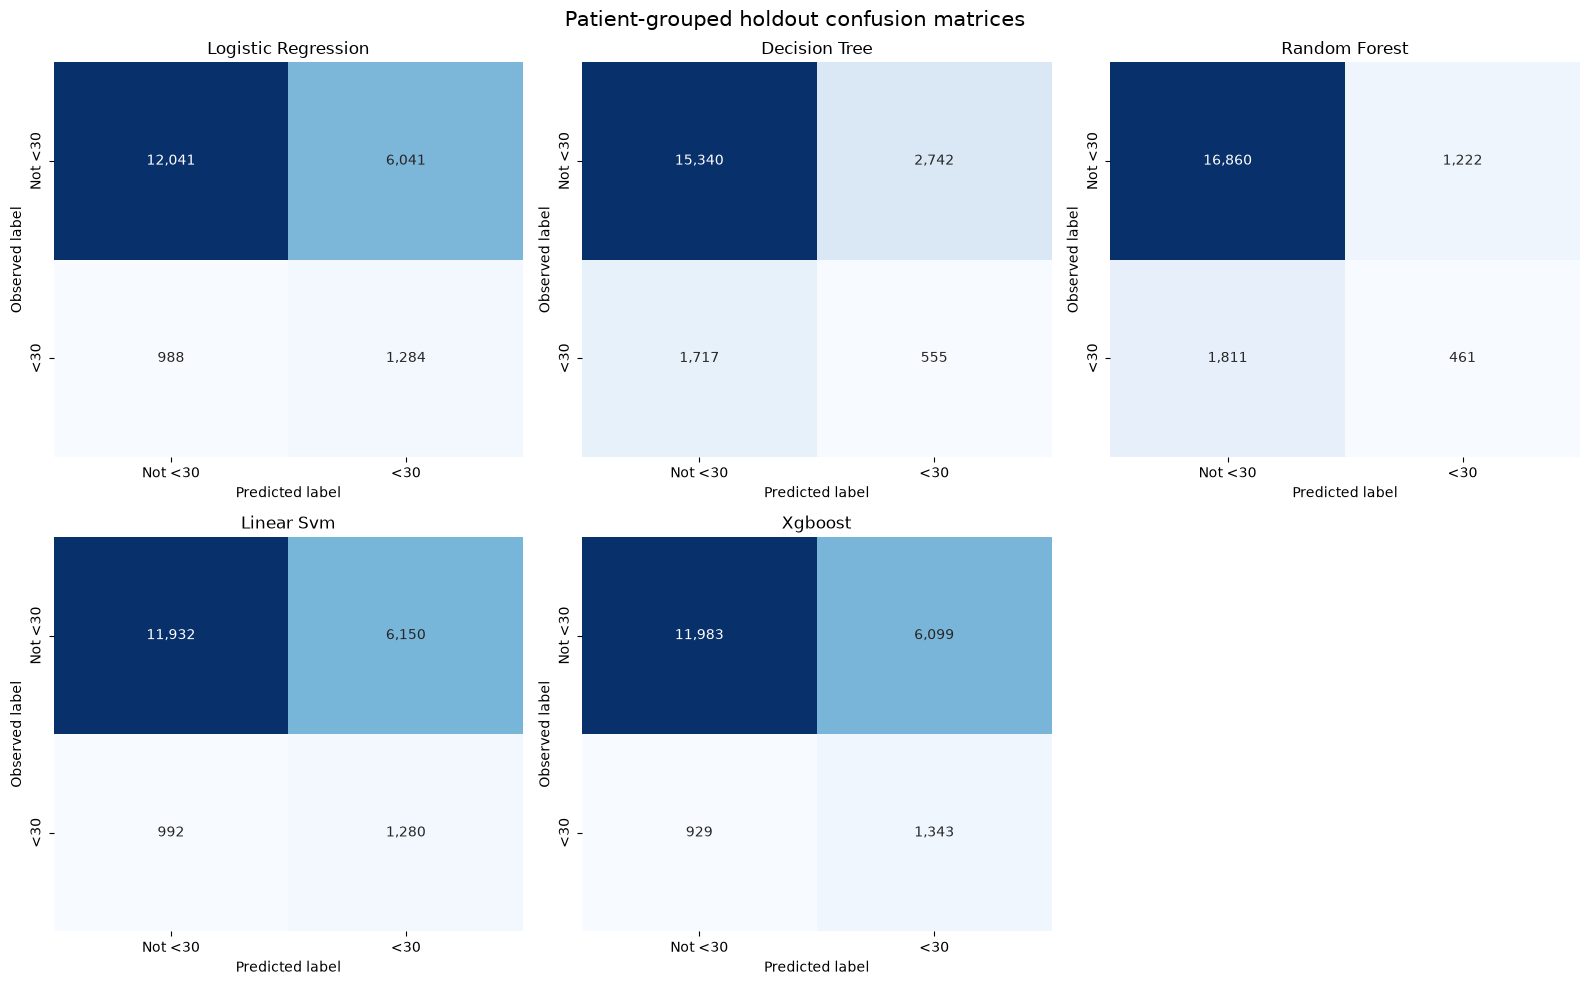

Comparison reports and confusion-matrix figure saved under reports/.


In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from backend.app.ml.diabetes.evaluation import compare_candidate_models

comparison = compare_candidate_models(
    training_run,
    data_split.X_train,
    data_split.y_train,
    data_split.groups_train,
    data_split.X_test,
    data_split.y_test,
    data_split.groups_test,
    cv_splits=3,
    random_state=42,
)

print("Holdout metrics; hard-label metrics use each estimator's default decision threshold.")
display(comparison.holdout_metrics.style.format({
    "accuracy": "{:.3f}",
    "precision": "{:.3f}",
    "recall": "{:.3f}",
    "f1": "{:.3f}",
    "roc_auc": "{:.3f}",
    "pr_auc": "{:.3f}",
    "training_seconds": "{:.1f}",
}))
print("Cross-validation metrics (mean and sample standard deviation, training folds only).")
display(comparison.cross_validation_metrics.style.format({"mean": "{:.3f}", "std": "{:.3f}"}))
print("Recall measures positive cases found; precision measures how many flagged cases are positive. Higher recall can come with more false positives.")
print("ROC-AUC and PR-AUC use scores; Linear SVM scores are not probabilities.")

figure_dir = PROJECT_ROOT / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
report_dir = PROJECT_ROOT / "reports"
comparison.holdout_metrics.to_csv(report_dir / "diabetes_holdout_metrics.csv")
comparison.cross_validation_metrics.to_csv(report_dir / "diabetes_cross_validation_metrics.csv")

matrix_rows = []
figure, axes = plt.subplots(2, 3, figsize=(16, 10))
for axis, (model_name, matrix) in zip(axes.flat, comparison.confusion_matrices.items()):
    sns.heatmap(
        matrix,
        annot=True,
        fmt=",d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Not <30", "<30"],
        yticklabels=["Not <30", "<30"],
        ax=axis,
    )
    axis.set(title=model_name.replace("_", " ").title(), xlabel="Predicted label", ylabel="Observed label")
    for actual_label, row in enumerate(matrix):
        for predicted_label, count in enumerate(row):
            matrix_rows.append({
                "model": model_name,
                "actual_label": actual_label,
                "predicted_label": predicted_label,
                "count": int(count),
            })
axes.flat[-1].axis("off")
figure.suptitle("Patient-grouped holdout confusion matrices", fontsize=15)
figure.tight_layout()
figure.savefig(figure_dir / "diabetes_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)
pd.DataFrame(matrix_rows).to_csv(report_dir / "diabetes_confusion_matrices.csv", index=False)
print("Comparison reports and confusion-matrix figure saved under reports/.")

## Phase 7: Bounded Hyperparameter Tuning

Logistic Regression is included as a comparatively simple, interpretable baseline; XGBoost is included as a more flexible boosted-tree candidate. Each gets four randomized parameter configurations evaluated with three patient-grouped folds on training data, using average precision (PR-AUC) as its within-candidate search objective. This is not an overall model ranking. The holdout is not used in tuning; best CV scores are tuning estimates, not independent performance claims.

In [5]:
from backend.app.ml.diabetes.tuning import tune_selected_candidates

tuning_run = tune_selected_candidates(
    training_run,
    data_split.X_train,
    data_split.y_train,
    data_split.groups_train,
    cv_splits=3,
    n_iter=4,
    random_state=42,
)

tuning_summary = tuning_run.summary.copy()
display(tuning_summary.style.format({
    "best_cv_mean": "{:.4f}",
    "best_cv_std": "{:.4f}",
}))

search_result_frames = []
for candidate_name, search in tuning_run.searches.items():
    candidate_results = pd.DataFrame(search.cv_results_)[
        ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    ].copy()
    candidate_results.insert(0, "candidate", candidate_name)
    search_result_frames.append(candidate_results)

search_results = pd.concat(search_result_frames, ignore_index=True)
report_dir = PROJECT_ROOT / "reports"
report_dir.mkdir(parents=True, exist_ok=True)
tuning_summary.to_csv(report_dir / "diabetes_tuning_summary.csv")
search_results.to_csv(report_dir / "diabetes_tuning_cv_results.csv", index=False)
print("Tuning used training folds only; the held-out partition was not passed to the search.")
print("No overall candidate model was selected, and no tuned model was serialized.")

,search_objective,best_cv_mean,best_cv_std,best_params,configurations_tested
candidate,,,,,
logistic_regression,average_precision,0.2152,0.0042,"{'classifier__class_weight': 'balanced', 'classifier__C': 0.1}",4
xgboost,average_precision,0.2219,0.0056,"{'classifier__subsample': 0.75, 'classifier__scale_pos_weight': 8.0, 'classifier__n_estimators': 160, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.06, 'classifier__colsample_bytree': 0.7}",4


Tuning used training folds only; the held-out partition was not passed to the search.
No overall candidate model was selected, and no tuned model was serialized.


## Phase 8: SHAP Explanations

Explanations below cover the tuned Logistic Regression and XGBoost candidates, not a selected production model. Global importance is computed on a reproducible sample of training rows; a few holdout rows are used only for local illustrations, not fitting or tuning. SHAP values are contributions to raw model output (log-odds for Logistic Regression, raw margin for XGBoost), not probability changes or causal effects. Displayed probabilities are separate model estimates. These explanations are educational and not medical advice.

c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


logistic_regression: SHAP output scale is log-odds; global mean absolute contributions:


,mean_absolute_shap_value
number_inpatient,0.212033
discharge_disposition_id_11,0.171728
payer_code___missing__,0.085308
discharge_disposition_id_3,0.079518
medical_specialty___missing__,0.072560
discharge_disposition_id_22,0.069435
discharge_disposition_id_1,0.060802
age_[70-80),0.057771
insulin_No,0.051377
diabetesMed_No,0.047977


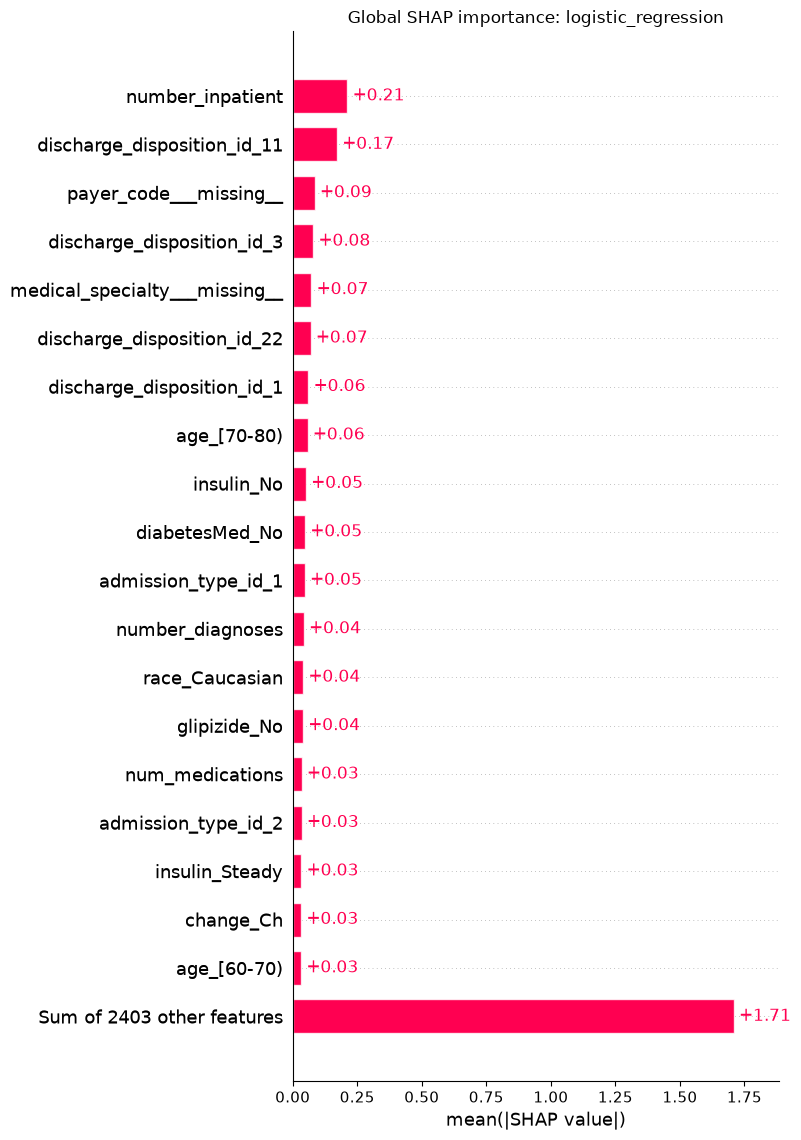

xgboost: SHAP output scale is raw margin; global mean absolute contributions:


,mean_absolute_shap_value
number_inpatient,0.273318
discharge_disposition_id_1,0.143792
discharge_disposition_id_11,0.135614
number_diagnoses,0.049563
discharge_disposition_id_22,0.038899
number_emergency,0.033087
payer_code___missing__,0.029971
time_in_hospital,0.028184
diabetesMed_No,0.024898
discharge_disposition_id_3,0.024419


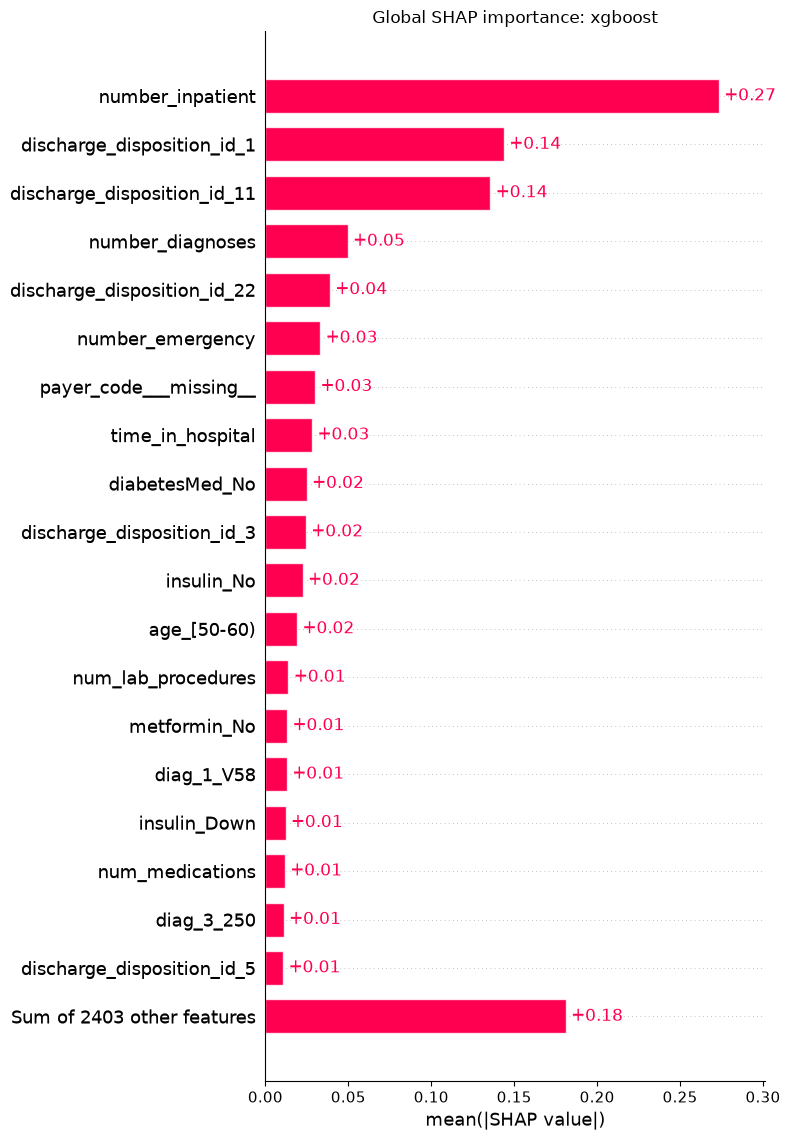

logistic_regression, example 1: model-estimated <30 probability = 59.1%


,feature,encoded_value,contribution,direction
0,discharge_disposition_id_2,1.000000,0.402190,toward <30 model output
1,number_inpatient,-0.503238,-0.200031,away from <30 model output
2,num_medications,3.939332,0.176955,toward <30 model output
3,diag_1_414,1.000000,0.167612,toward <30 model output
4,payer_code___missing__,0.000000,-0.082689,away from <30 model output
5,discharge_disposition_id_1,0.000000,0.076363,toward <30 model output
6,medical_specialty_Radiologist,1.000000,0.075299,toward <30 model output
7,medical_specialty___missing__,0.000000,-0.073849,away from <30 model output
8,num_procedures,2.740353,-0.071431,away from <30 model output
9,age_[60-70),1.000000,0.065548,toward <30 model output


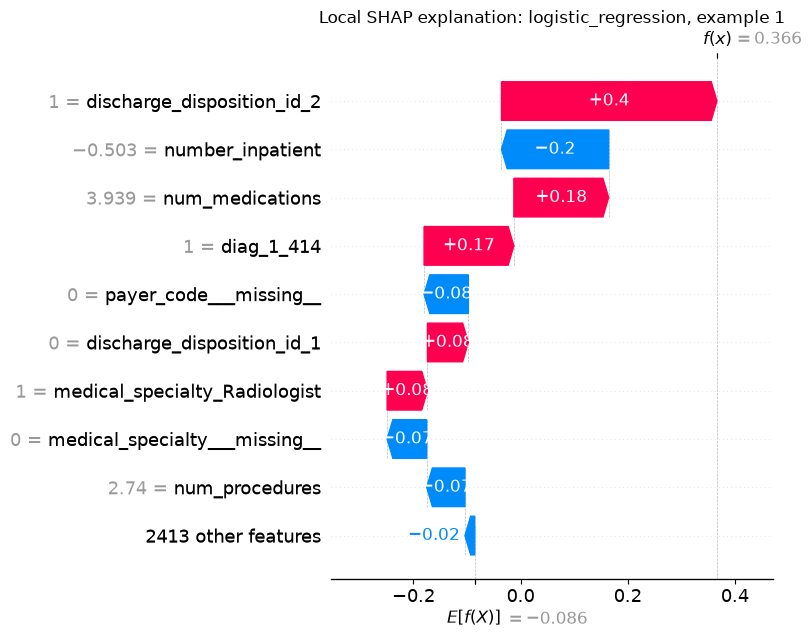

xgboost, example 1: model-estimated <30 probability = 53.1%


,feature,encoded_value,contribution,direction
0,number_inpatient,-0.503238,-0.236797,away from <30 model output
1,discharge_disposition_id_1,0.000000,0.181311,toward <30 model output
2,discharge_disposition_id_2,1.000000,0.085404,toward <30 model output
3,number_diagnoses,0.817798,0.050320,toward <30 model output
4,payer_code___missing__,0.000000,-0.037444,away from <30 model output
5,discharge_disposition_id_22,0.000000,-0.033727,away from <30 model output
6,discharge_disposition_id_11,0.000000,0.023886,toward <30 model output
7,admission_type_id_3,1.000000,0.018669,toward <30 model output
8,diabetesMed_No,0.000000,0.018101,toward <30 model output
9,insulin_No,0.000000,0.017231,toward <30 model output


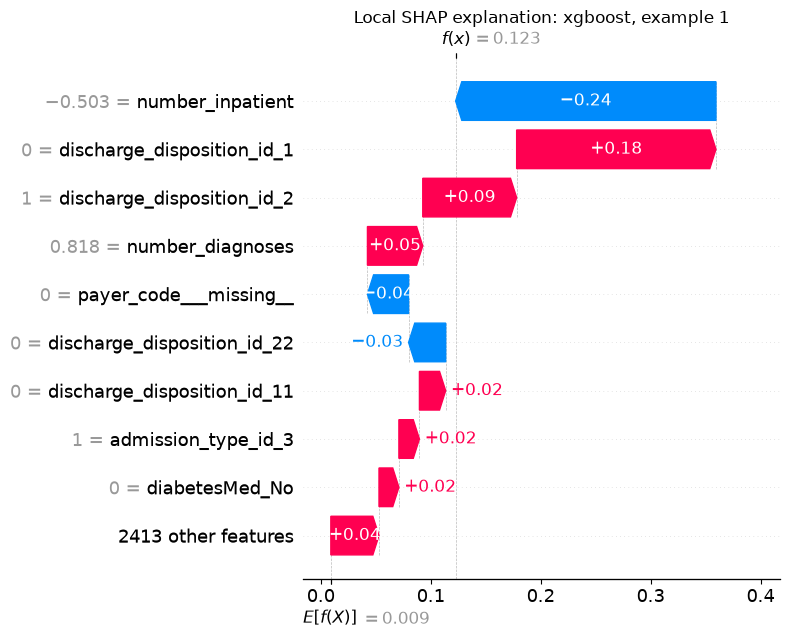

SHAP global/local reports saved; feature contributions describe model output, not causes.


In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import shap
from IPython.display import display

from backend.app.ml.diabetes.explanation import explain_pipeline, top_local_contributions

background_rows = data_split.X_train.sample(n=100, random_state=42)
global_rows = data_split.X_train.sample(n=200, random_state=43)
local_rows = data_split.X_test.sample(n=5, random_state=44)

shap_global = {}
shap_local = {}
for candidate_name, search in tuning_run.searches.items():
    fitted_pipeline = search.best_estimator_
    shap_global[candidate_name] = explain_pipeline(
        fitted_pipeline,
        background_rows,
        global_rows,
        background_size=100,
    )
    shap_local[candidate_name] = explain_pipeline(
        fitted_pipeline,
        background_rows,
        local_rows,
        background_size=100,
    )

figure_dir = PROJECT_ROOT / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
report_dir = PROJECT_ROOT / "reports"
global_records = []
local_records = []

for candidate_name, result in shap_global.items():
    print(f"{candidate_name}: SHAP output scale is {result.output_scale}; global mean absolute contributions:")
    display(result.global_importance.head(12).to_frame())
    for feature, importance in result.global_importance.items():
        global_records.append({
            "candidate": candidate_name,
            "feature": feature,
            "mean_absolute_shap_value": importance,
        })
    shap.plots.bar(result.shap_values, max_display=20, show=False)
    plt.title(f"Global SHAP importance: {candidate_name}")
    plt.tight_layout()
    plt.savefig(figure_dir / f"diabetes_shap_global_{candidate_name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

for candidate_name, result in shap_local.items():
    probability = float(result.positive_probabilities.iloc[0])
    print(f"{candidate_name}, example 1: model-estimated <30 probability = {probability:.1%}")
    local_table = top_local_contributions(result, row_index=0, max_features=10)
    display(local_table)
    for record in local_table.to_dict(orient="records"):
        local_records.append({
            "candidate": candidate_name,
            "example_number": 1,
            "model_probability_readmitted_within_30d": probability,
            "output_scale": result.output_scale,
            **record,
        })
    shap.plots.waterfall(result.shap_values[0], max_display=10, show=False)
    plt.title(f"Local SHAP explanation: {candidate_name}, example 1")
    plt.tight_layout()
    plt.savefig(figure_dir / f"diabetes_shap_local_{candidate_name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

pd.DataFrame(global_records).to_csv(report_dir / "diabetes_shap_global_importance.csv", index=False)
pd.DataFrame(local_records).to_csv(report_dir / "diabetes_shap_local_contributions.csv", index=False)
print("SHAP global/local reports saved; feature contributions describe model output, not causes.")

## Phase 9: Save The Demonstration Model

The tuned XGBoost pipeline is selected for the educational demo based on patient-grouped CV evidence: it had the strongest baseline PR-AUC and recall among the tested candidates, and the bounded tuning search retained the stronger within-candidate PR-AUC result. This is a documented trade-off for an imbalanced readmission task, not a composite “best model” score or clinical endorsement. The holdout was previously inspected during baseline comparison; its tuned-model metrics below are exploratory and are not an untouched external validation. The fitted model and preprocessor are saved separately with source hash, target, features, and metrics in metadata.

In [7]:
import hashlib
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

from backend.app.ml.diabetes.persistence import save_diabetes_artifacts

selected_search = tuning_run.searches["xgboost"]
selected_model = selected_search.best_estimator_
holdout_predictions = selected_model.predict(data_split.X_test)
holdout_probabilities = selected_model.predict_proba(data_split.X_test)[:, 1]
tuned_holdout_metrics = {
    "accuracy": float(accuracy_score(data_split.y_test, holdout_predictions)),
    "precision": float(precision_score(data_split.y_test, holdout_predictions, zero_division=0)),
    "recall": float(recall_score(data_split.y_test, holdout_predictions, zero_division=0)),
    "f1": float(f1_score(data_split.y_test, holdout_predictions, zero_division=0)),
    "roc_auc": float(roc_auc_score(data_split.y_test, holdout_probabilities)),
    "pr_auc": float(average_precision_score(data_split.y_test, holdout_probabilities)),
    "confusion_matrix_labels_0_1": confusion_matrix(
        data_split.y_test,
        holdout_predictions,
        labels=[0, 1],
    ).tolist(),
    "partition_note": "Previously inspected in baseline comparison; exploratory, not untouched external validation.",
}

source_path = PROJECT_ROOT / "data" / "raw" / "diabetes" / "source" / "diabetic_data.csv"
source_sha256 = hashlib.sha256(source_path.read_bytes()).hexdigest()
xgb_tuning_summary = tuning_run.summary.loc["xgboost"]
selection_rationale = (
    "Selected for the educational demonstration using patient-grouped training CV, "
    "not a composite best-model score. Among the five baseline candidates, XGBoost "
    "had the highest 3-fold CV PR-AUC (0.222 +/- 0.003) and recall (0.569 +/- 0.007), "
    "which are relevant to the uncommon <30 class. Its bounded tuning search achieved "
    f"best CV average precision {xgb_tuning_summary['best_cv_mean']:.4f} +/- "
    f"{xgb_tuning_summary['best_cv_std']:.4f}. SHAP explanations are included, but "
    "this more complex model is not clinically validated and SHAP does not establish causality."
)

model_metrics = {
    "tuning_cv_best_average_precision": {
        "mean": float(xgb_tuning_summary["best_cv_mean"]),
        "std": float(xgb_tuning_summary["best_cv_std"]),
        "folds": 3,
        "configurations_tested": int(xgb_tuning_summary["configurations_tested"]),
        "selection_note": "Best configuration from the bounded search; subject to search-selection optimism.",
    },
    "post_selection_holdout": tuned_holdout_metrics,
}

artifact_directory = PROJECT_ROOT / "backend" / "trained_models"
model_metadata = save_diabetes_artifacts(
    selected_model,
    artifact_directory,
    model_version="1.0",
    source_sha256=source_sha256,
    metrics=model_metrics,
    selection_rationale=selection_rationale,
)
print("Persisted selected demonstration model:", model_metadata["artifacts"])
print("Estimator:", model_metadata["algorithm"])
print("Input features:", len(model_metadata["features"]))
print("Transformed features:", model_metadata["transformed_feature_count"])
print("Tuned holdout metrics (previously observed partition):", tuned_holdout_metrics)
print("Metadata:", artifact_directory / "model_metadata.json")

Persisted selected demonstration model: {'model': 'diabetes_model.joblib', 'preprocessor': 'diabetes_preprocessor.joblib'}
Estimator: XGBClassifier
Input features: 46
Transformed features: 2422
Tuned holdout metrics (previously observed partition): {'accuracy': 0.6382529232583276, 'precision': 0.1768439761330456, 'recall': 0.6131161971830986, 'f1': 0.27450980392156865, 'roc_auc': 0.6734110628264666, 'pr_auc': 0.21774345585365978, 'confusion_matrix_labels_0_1': [[11598, 6484], [879, 1393]], 'partition_note': 'Previously inspected in baseline comparison; exploratory, not untouched external validation.'}
Metadata: c:\Users\DELL\OneDrive\Desktop\Python Projects\Medical Disease Prediction\backend\trained_models\model_metadata.json
